# Baseline: ADR Prediction with Perturb-Seqr Data

PCA → feature selection → RandomForest → cross-validated AUROC.

**Data:** Drugs from [Perturb-Seqr](https://perturbseqr.maayanlab.cloud/) datasets with both GMT signatures and OnSIDES ADR labels.

**Further reading:** See [SEP-L1000](https://doi.org/10.1093/bioinformatics/btw168) (Wang et al., *Bioinformatics*, 2016).

In [1]:
%matplotlib inline
# Imports
## Data processing
import pandas as pd
import numpy as np
import scipy as sp
import gzip # to read GMT files
import warnings # to suppress sklearn convergence warnings
from maayanlab_bioinformatics.parse import gmt_read_iter # GMT parsing
from maayanlab_bioinformatics.harmonization.homologs import mouse_human_homologs # mouse->human ortholog mapping
from pathlib import Path # to handle file paths
from collections import defaultdict, Counter
from typing import NamedTuple, Callable
## Machine Learning
import sklearn as sk
from sklearn import (
    preprocessing, 
    decomposition, 
    ensemble, 
    model_selection, 
    pipeline,
    metrics, 
    manifold, 
    feature_selection, 
    linear_model, 
    tree, 
    svm, 
    calibration,
)
warnings.filterwarnings("ignore", category=sk.exceptions.ConvergenceWarning)
## Plotting
from matplotlib import pyplot as plt
from matplotlib_venn import venn2 # trainable venn diagrams
from matplotlib.colors import LinearSegmentedColormap # heatmaps
## Utility
import re
import json
from IPython.display import display

# Paths
PERTURBSEQR_ROOT = Path.cwd().parent  # notebook lives in PerturbSeqr/predict/
PREDICT_DIR = PERTURBSEQR_ROOT / "predict"
GMT_DIR = PERTURBSEQR_ROOT / "db" / "data" / "drug_perturbation"
DATA_DIR = PREDICT_DIR / "data"

# Configuration
rng = 2018
N_TARGETS = 50  # number of top ADRs to evaluate (set lower for quick runs)
SKIP_DATASETS: set[str] = set()  # creeds-chem is mouse-derived; included via to_human ortholog mapping below

## Utility Functions: Feature Construction

In [2]:
def parse_perturbseqr_signatures(
    gmt_file: Path,
    trainable_items: set[str] | None = None,
    normalize_pert: Callable[[str], str] = str.lower,
    normalize_gene: Callable[[str], str] = lambda g: g,
) -> tuple[defaultdict[str, set[str]], defaultdict[str, set[str]]]:
    up: defaultdict[str, set[str]] = defaultdict(set)
    down: defaultdict[str, set[str]] = defaultdict(set)
    with gzip.open(gmt_file, "rt") as gmt_stream:
        for term, geneset in gmt_read_iter(gmt_stream):
            term = term.split("\t", 1)[0]
            term_lower = term.lower()
            if term_lower.endswith(" up"):
                direction = "up"
            elif term_lower.endswith((" down", " dn")):
                direction = "down"
            else:
                continue
            pert = normalize_pert(term.split("::")[0].strip())
            if trainable_items is not None and pert not in trainable_items:
                continue
            (up if direction == "up" else down)[pert].update(normalize_gene(g) for g in geneset.keys())
    return up, down

def build_feature_matrix(
    gmt_path: Path,
    trainable_items: set[str] | None = None,
    skip_datasets: set[str] | None = None,
    normalize_pert: Callable[[str], str] = str.lower,
    normalize_gene: Callable[[str], str] = lambda g: g,
) -> pd.DataFrame | None:
    """Build item × gene up/down binary matrix from a GMT file or directory of GMTs.
    Returns a DataFrame with rows = items, columns = [GENE_up..., GENE_down...].
    """
    skip_datasets = skip_datasets or set()
    up_all: defaultdict[str, set[str]] = defaultdict(set)
    down_all: defaultdict[str, set[str]] = defaultdict(set)

    gmt_files = sorted(gmt_path.glob("*.gmt.gz")) if gmt_path.is_dir() else [gmt_path]
    for gmt_file in gmt_files:
        if gmt_file.stem.replace(".gmt", "") in skip_datasets:
            continue
        up, down = parse_perturbseqr_signatures(gmt_file, trainable_items, normalize_pert, normalize_gene)
        for k, v in up.items():
            up_all[k].update(v)
        for k, v in down.items():
            down_all[k].update(v)

    items = sorted(set(up_all) | set(down_all))
    if not items:
        return None
    all_genes = sorted({g for d in (up_all, down_all) for genes in d.values() for g in genes})
    cols = [f"{g}_up" for g in all_genes] + [f"{g}_down" for g in all_genes]

    rows = []
    for item in items:
        row = [1 if g in up_all.get(item, set()) else 0 for g in all_genes] + \
              [1 if g in down_all.get(item, set()) else 0 for g in all_genes]
        rows.append(row)
    return pd.DataFrame(rows, index=items, columns=cols, dtype=np.int8)


## Utility Functions: Target Construction

In [3]:
def build_target(
    adr_id: str,
    X: pd.DataFrame,
    name_to_rxnorm: dict[str, str],
    rxnorm_to_adrs: dict[str, list[str]],
) -> np.ndarray:
    """Build binary target vector for an ADR.

    Parameters:
    adr_id: MedDRA preferred-term ID of the target ADR (e.g. "10002034" for Anaemia).
    X: Feature matrix whose index is drug names.
    name_to_rxnorm: Mapping from drug name → OnSIDES RxNorm ingredient ID.
    rxnorm_to_adrs: Mapping from RxNorm ingredient ID → list of MedDRA ADR IDs that drug causes.

    Returns: Binary vector where y[i] = 1 if drug X.index[i] causes adr_id, else 0.
    """
    y = np.zeros(len(X), dtype=np.int8)
    for i, drug in enumerate(X.index):
        rxnorm_id = str(name_to_rxnorm[drug])
        if adr_id in rxnorm_to_adrs[rxnorm_id]:
            y[i] = 1
    return y

## Utility Functions: Model and Cross-Validation

`build_pipeline` is the pipeline definition (PCA → LinearSVC L1 feature selection → RandomForest → CalibratedClassifierCV) used by both `cv_auroc` and the standalone fit in the single-target demo.

In [4]:
def build_pipeline(
    cv,
    n_components: int = 64,
    random_state: int = 2018,
) -> sk.calibration.CalibratedClassifierCV:
    return sk.calibration.CalibratedClassifierCV(
        sk.pipeline.Pipeline([
            ('reduce_dim', sk.decomposition.PCA(n_components=n_components, random_state=random_state)),
            ('feature_selection', sk.feature_selection.SelectFromModel(
                sk.svm.LinearSVC(loss="squared_hinge", penalty="l1", dual=False, max_iter=5000))),
            ('clf', sk.ensemble.RandomForestClassifier(random_state=random_state)),
        ]),
        cv=cv,
    )

def plot_cv_roc(
    fold_predictions: list[tuple[np.ndarray, np.ndarray, float]],
    mean_auroc: float,
    std_auroc: float,
    title: str | None = None,
) -> None:
    """plotting cross-validated ROC curve"""
    fig, ax = plt.subplots()
    tprs = []
    mean_fpr = np.linspace(0, 1, 100)
    for fold, (y_test, y_prob, fold_auc) in enumerate(fold_predictions):
        fpr, tpr, _ = sk.metrics.roc_curve(y_test, y_prob)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        ax.plot(fpr, tpr, alpha=0.4, label=f'ROC Fold {fold} (AUC={fold_auc:.3f})')
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    ax.plot(mean_fpr, mean_tpr, color='b', lw=2, alpha=.8,
            label=fr'Mean ROC (AUC = {mean_auroc:.2f} $\pm$ {std_auroc:.2f})')
    std_tpr = np.std(tprs, axis=0)
    ax.fill_between(mean_fpr, np.maximum(mean_tpr - std_tpr, 0),
                    np.minimum(mean_tpr + std_tpr, 1), color='grey', alpha=.2)
    ax.plot([0, 1], [0, 1], '--', label='Luck')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    if title:
        ax.set_title(title)
    ax.legend(loc='lower right')
    plt.tight_layout()

class CVResult(NamedTuple):
    mean_auroc: float
    std_auroc: float
    fold_aurocs: list[float]
    oof_predictions: np.ndarray  # out-of-fold predict_proba for each row in X

def cv_auroc(
    X_vals: np.ndarray,
    y: np.ndarray,
    n_splits: int = 3,
    n_components: int = 64,
    random_state: int = 2018,
    *,
    plot: bool = False,
    plot_title: str | None = None,
) -> CVResult:
    """Stratified k-fold CV with PCA → LinearSVC L1 feature selection → RandomForest → CalibratedClassifierCV.

    Returns CVResult(mean_auroc, std_auroc, fold_aurocs, oof_predictions). The
    oof_predictions array contains out-of-fold predict_proba for each row in X
    — every entry is from the fold where that row was held out.

    When plot=True, also renders the cross-validated ROC curve as a side effect.
    """
    # Cap n_components considering smaller datasets may have very few training samples in each fold and PCA can't have more components than samples - 1.
    inner_train_size = int(X_vals.shape[0] * ((n_splits - 1) / n_splits) ** 2)
    n_comp = min(n_components, inner_train_size - 1, X_vals.shape[1])
    cv = sk.model_selection.StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    model = build_pipeline(cv, n_components=n_comp, random_state=random_state)
    fold_aurocs = []
    fold_predictions = [] if plot else None
    oof_predictions = np.zeros(len(y), dtype=np.float64)
    for train_idx, test_idx in cv.split(X_vals, y):
        model.fit(X_vals[train_idx], y[train_idx])
        y_prob = model.predict_proba(X_vals[test_idx])[:, 1]
        fold_auc = sk.metrics.roc_auc_score(y[test_idx], y_prob)
        fold_aurocs.append(fold_auc)
        oof_predictions[test_idx] = y_prob
        if plot:
            fold_predictions.append((y[test_idx], y_prob, fold_auc))
    mean_auroc = float(np.mean(fold_aurocs))
    std_auroc = float(np.std(fold_aurocs))
    if plot:
        plot_cv_roc(fold_predictions, mean_auroc, std_auroc, title=plot_title)
    return CVResult(mean_auroc, std_auroc, fold_aurocs, oof_predictions)

def summarize_aurocs(df: pd.DataFrame, auroc_col: str = "auroc") -> dict:
    """Compute summary statistics"""
    s = df[auroc_col].dropna()
    return {
        "n": len(s),
        "mean": float(s.mean()),
        "median": float(s.median()),
        "max": float(s.max()),
        "above_0.6": int((s > 0.6).sum()),
        "above_0.7": int((s > 0.7).sum()),
    }

def evaluate_targets(
    X: pd.DataFrame,
    target_builder: Callable,
    targets: list[tuple],
    min_pos: int = 10,
    label_field: str | None = None,
    verbose: bool = True,
) -> pd.DataFrame:
    """Run cv_auroc for each target and return a results DataFrame"""
    results = []
    for target_arg, metadata in targets:
        y = target_builder(target_arg, X)
        n_pos = int(y.sum())
        if n_pos < min_pos or n_pos > len(y) - min_pos:
            continue
        try:
            auroc = cv_auroc(X.values, y).mean_auroc
        except Exception:
            auroc = np.nan
        results.append({**metadata, "n_positive": n_pos, "auroc": auroc})
        if verbose:
            label = metadata.get(label_field, "?") if label_field else next(iter(metadata.values()))
            print(f"  {label}: AUROC={auroc:.3f} (n={n_pos})")
    return pd.DataFrame(results)

## Inputs

Load the drug mapping (Perturb-Seqr drugs ↔ OnSIDES ingredients) and the OnSIDES ADR labels, then select an ADR to predict in the single-target demo.

In [5]:
mapping_df = pd.read_parquet(DATA_DIR / "drug_mapping.parquet")
onsides_ingredients = pd.read_csv(
    DATA_DIR / "onsides" / "extracted" / "csv" / "vocab_rxnorm_ingredient.csv",
    usecols=["rxnorm_id"],
)
onsides_ingredient_count = onsides_ingredients["rxnorm_id"].nunique()
rxnorm_to_adrs = json.load(open(DATA_DIR / "ingredient_adrs.json"))
meddra_vocab = pd.read_parquet(DATA_DIR / "meddra_vocab_used.parquet")
meddra_names = dict(zip(meddra_vocab["meddra_id"].astype(str), meddra_vocab["meddra_name"]))

adr_freq = Counter(adr for adrs in rxnorm_to_adrs.values() for adr in adrs)

# Single-target demo: Anaemia 
TARGET_ADR_ID = "10002034"
TARGET_ADR_NAME = meddra_names[TARGET_ADR_ID]

name_to_rxnorm = mapping_df.set_index("perturbseqr_name")["rxnorm_id"].to_dict()
trainable_names = set(mapping_df["perturbseqr_name"].str.lower())

print(f"OnSIDES ingredients: {onsides_ingredient_count:,}")
print(f"Trainable drugs (mapping table): {len(mapping_df):,}")
print(f"Unique ADR terms: {len(adr_freq):,}")
print(f"\nTarget: {TARGET_ADR_NAME} (MedDRA {TARGET_ADR_ID})")
print(f"Drugs causing this ADR: {adr_freq[TARGET_ADR_ID]} / {len(mapping_df)}")

# Mouse->human ortholog map (MGI), used as the responding-gene normalizer for perturbation parsing.
# Several drug datasets (creeds-chem, parts of rummageo-chem, ginkgo-bioworks) include mouse sig.
m2h_df = mouse_human_homologs(uppercase=True)
human_symbols = set(m2h_df["human"])
mouse_only_df = m2h_df[~m2h_df["mouse"].isin(human_symbols)]
mouse_to_human = dict(zip(mouse_only_df["mouse"], mouse_only_df["human"]))

def to_human(symbol: str) -> str:
    """Uppercase a gene symbol and map mouse-only ortholog to its human equivalent."""
    s = symbol.upper()
    return mouse_to_human.get(s, s)

print(f"\nMouse-only -> human ortholog map: {len(mouse_to_human):,} entries")


OnSIDES ingredients: 2,562
Trainable drugs (mapping table): 1,022
Unique ADR terms: 6,344

Target: Anaemia (MedDRA 10002034)
Drugs causing this ADR: 274 / 1022



Mouse-only -> human ortholog map: 3,213 entries


## Trainable Drug Coverage

The source collections use different identifiers: Perturb-Seqr perturbation names and OnSIDES RxNorm ingredients. Their overlap is therefore defined by the curated name and PubChem mapping used to build the training cohort, rather than by a raw string-set intersection.

In [6]:
per_dataset_drugs = {}
all_perturbed_drugs: set[str] = set()
for gmt_file in sorted(GMT_DIR.glob("*.gmt.gz")):
    ds = gmt_file.stem.replace(".gmt", "")
    if ds in SKIP_DATASETS:
        continue
    up, down = parse_perturbseqr_signatures(gmt_file, normalize_gene=to_human)
    drugs = set(up) | set(down)
    per_dataset_drugs[ds] = drugs
    all_perturbed_drugs.update(drugs)
    print(f"{ds}: {len(drugs):,} unique perturbed drugs")

# The mapping table contains Perturb-Seqr names already matched to OnSIDES ingredients.
trainable = all_perturbed_drugs & trainable_names
print(f"\nTotal Perturb-Seqr drugs: {len(all_perturbed_drugs):,}")
print(f"OnSIDES ingredients: {onsides_ingredient_count:,}")
print(f"Mapped Perturb-Seqr names: {len(trainable_names):,}")
print(f"Trainable in current corpus: {len(trainable):,}")


creeds-chem: 270 unique perturbed drugs


deepcover-moa: 874 unique perturbed drugs


ginkgo-bioworks: 1,294 unique perturbed drugs


lincs-l1000-cp: 5,888 unique perturbed drugs


microarrays-cmap: 1,309 unique perturbed drugs


nibr-drug-seq: 4,046 unique perturbed drugs


rummageo-chem: 279 unique perturbed drugs


sciplex: 188 unique perturbed drugs


tahoe-100m: 378 unique perturbed drugs

Total Perturb-Seqr drugs: 11,969
OnSIDES ingredients: 2,562
Mapped Perturb-Seqr names: 1,021
Trainable in current corpus: 1,011


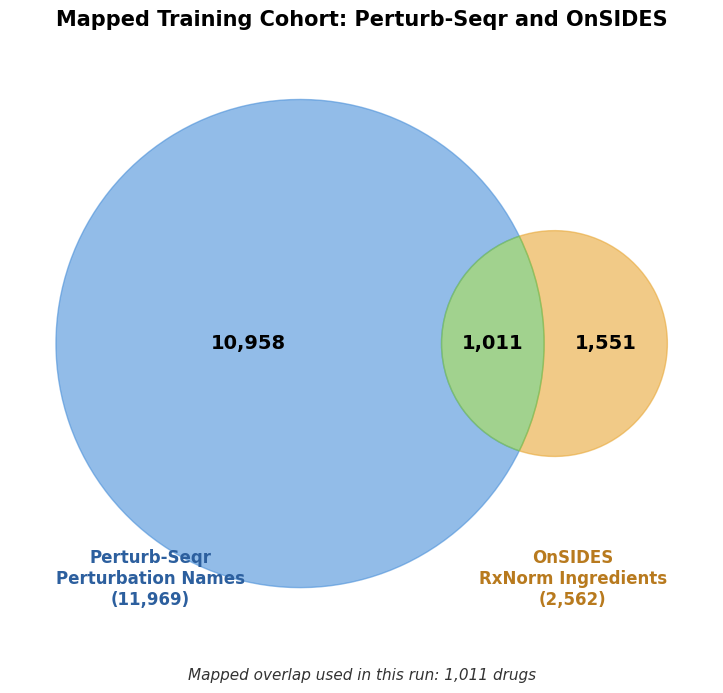

In [7]:
# Mapping-based Venn diagram for the training cohort
fig, ax = plt.subplots(figsize=(10, 7))

n_perturbseqr = len(all_perturbed_drugs)
n_onsides = onsides_ingredient_count
n_trainable = len(trainable)
assert n_trainable <= min(n_perturbseqr, n_onsides)

v = venn2(
    subsets=(n_perturbseqr - n_trainable, n_onsides - n_trainable, n_trainable),
    set_labels=("", ""),
    ax=ax,
)
v.get_patch_by_id("10").set_color("#4A90D9")
v.get_patch_by_id("10").set_alpha(0.6)
v.get_patch_by_id("01").set_color("#E8A838")
v.get_patch_by_id("01").set_alpha(0.6)
v.get_patch_by_id("11").set_color("#7ABF5E")
v.get_patch_by_id("11").set_alpha(0.7)
venn_counts = {
    "10": n_perturbseqr - n_trainable,
    "01": n_onsides - n_trainable,
    "11": n_trainable,
}
for label_id, count in venn_counts.items():
    label = v.get_label_by_id(label_id)
    label.set_text(f"{count:,}")
    label.set_fontsize(14)
    label.set_fontweight("bold")

ax.text(0.2, 0.05, f"Perturb-Seqr\nPerturbation Names\n({n_perturbseqr:,})",
        ha="center", fontsize=12, fontweight="bold", color="#2C5F9E", transform=ax.transAxes)
ax.text(0.8, 0.05, f"OnSIDES\nRxNorm Ingredients\n({n_onsides:,})",
        ha="center", fontsize=12, fontweight="bold", color="#B87A1E", transform=ax.transAxes)
ax.set_title("Mapped Training Cohort: Perturb-Seqr and OnSIDES", fontsize=15, fontweight="bold", pad=20)
ax.text(0.5, -0.08, f"Mapped overlap used in this run: {n_trainable:,} drugs",
        ha="center", fontsize=11, style="italic", color="#333", transform=ax.transAxes)

plt.tight_layout()
plt.savefig(DATA_DIR / "baseline_venn.png", dpi=150, bbox_inches="tight")
plt.show()

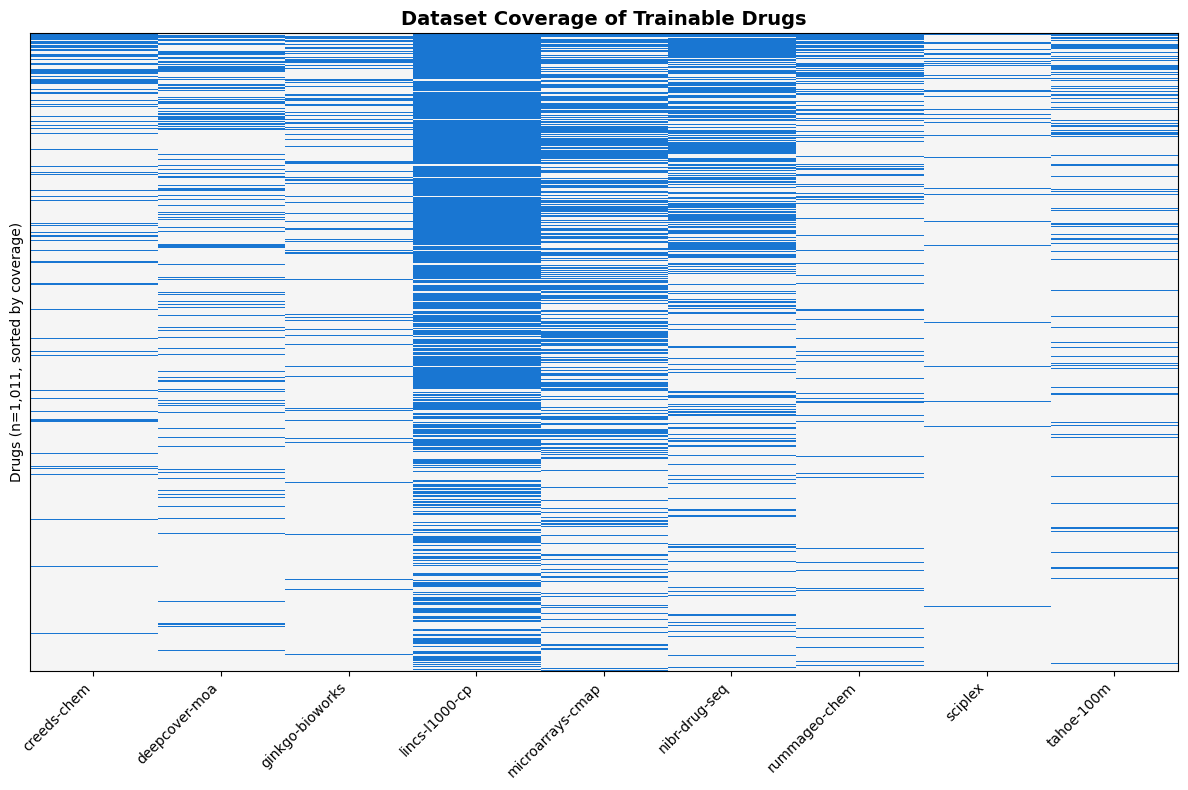


Datasets per trainable drug:
  1 dataset(s): 351 drugs
  2 dataset(s): 307 drugs
  3 dataset(s): 189 drugs
  4 dataset(s): 101 drugs
  5 dataset(s): 39 drugs
  6 dataset(s): 18 drugs
  7 dataset(s): 6 drugs


In [8]:
# Per-dataset coverage heatmap (drug × dataset binary matrix)
datasets_sorted = sorted(per_dataset_drugs.keys())
coverage = pd.DataFrame(
    {ds: [1 if d in per_dataset_drugs[ds] else 0 for d in sorted(trainable)] for ds in datasets_sorted},
    index=sorted(trainable),
)
# Sort drugs by total dataset coverage (most covered first)
coverage["total"] = coverage.sum(axis=1)
coverage = coverage.sort_values("total", ascending=False).drop(columns="total")

fig, ax = plt.subplots(figsize=(12, 8))
cmap = LinearSegmentedColormap.from_list("custom", ["#f5f5f5", "#1976D2"])
ax.imshow(coverage.values, aspect="auto", cmap=cmap, interpolation="nearest")
ax.set_xticks(range(len(coverage.columns)))
ax.set_xticklabels(coverage.columns, rotation=45, ha="right", fontsize=10)
ax.set_ylabel(f"Drugs (n={len(coverage):,}, sorted by coverage)")
ax.set_yticks([])
ax.set_title("Dataset Coverage of Trainable Drugs", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(DATA_DIR / "baseline_coverage_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Distribution of dataset counts
n_ds = coverage.sum(axis=1)
print(f"\nDatasets per trainable drug:")
for i in range(1, int(n_ds.max()) + 1):
    count = (n_ds == i).sum()
    if count > 0:
        print(f"  {i} dataset(s): {count:,} drugs")

## Combined Feature Matrix

Build a single drug × gene up/down binary matrix combining all datasets (excluding skipped ones).

In [9]:
X = build_feature_matrix(GMT_DIR, trainable_items=trainable_names, skip_datasets=SKIP_DATASETS, normalize_gene=to_human)
print(f"X shape: {X.shape} (drugs × gene-direction features)")
print(f"Sparsity: {100*(1 - X.values.sum()/np.prod(X.shape)):.1f}%")
print(f"Mean features per drug: {X.sum(axis=1).mean():.0f}")
display(X.iloc[:5, :8])


X shape: (1011, 41544) (drugs × gene-direction features)
Sparsity: 86.5%
Mean features per drug: 5616


,1110058L19RIK_up,1200007C13RIK_up,1500012F01RIK_up,1700052M09RIK_up,2010107E04RIK_up,2610319H10RIK_up,2900054C01RIK_up,3000002C10RIK_up
abacavir,0,0,0,0,0,0,0,0
abemaciclib,0,0,0,0,0,0,0,0
abiraterone,0,0,0,0,0,0,0,0
acalabrutinib,0,0,0,0,0,0,0,0
acamprosate,0,0,0,0,0,0,0,0


## Single ADR Demo: Anaemia

Run the full pipeline on a single target ADR to inspect ROC curve, confusion matrix, and novel predictions. Mirrors the harmonizome-ml `output.ipynb` flow.

In [10]:
# Build target vector for the selected ADR
y = build_target(TARGET_ADR_ID, X, name_to_rxnorm, rxnorm_to_adrs)

print(f"Target: {TARGET_ADR_NAME} (MedDRA {TARGET_ADR_ID})")
print(f"Input shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Class balance: {y.sum()} positive ({100*y.mean():.1f}%), {(y==0).sum()} negative ({100*(1-y.mean()):.1f}%)")

Target: Anaemia (MedDRA 10002034)
Input shape: (1011, 41544)
Target shape: (1011,)
Class balance: 272 positive (26.9%), 739 negative (73.1%)


### ROC Curve

Cross-validated ROC curve. Low fold variance and high AUC indicate a well-generalized model.

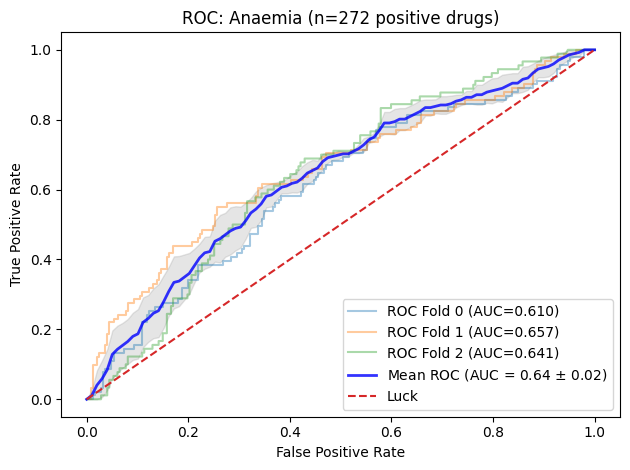

In [11]:
# Run cv_auroc with plot=True to render the ROC curve. The returned CVResult includes
# out-of-fold predictions for the confusion matrix and novel
# predictions table: every prediction is from the CV fold where that drug was held out.
cv_result = cv_auroc(
    X.values, y,
    plot=True,
    plot_title=f"ROC: {TARGET_ADR_NAME} (n={int(y.sum())} positive drugs)",
)
mean_auroc, std_auroc, _, oof_predictions = cv_result

In [12]:
# Statistical significance check
z = (mean_auroc - 0.5) / std_auroc if std_auroc > 0 else float("inf")
cl = sp.stats.norm.cdf(z) * 100
ci = sp.stats.norm.interval(0.95, loc=mean_auroc, scale=std_auroc)
print('Confidence interval (95%):', ci)
print("We are %0.3f %% confident the model's results are not just chance." % cl)
if cl > 95:
    print('Statistically significant. These results can be trusted.')
else:
    print('Not statistically significant. These results should not be trusted.')

Confidence interval (95%): (np.float64(0.5978098261455501), np.float64(0.6742491518184343))
We are 100.000 % confident the model's results are not just chance.
Statistically significant. These results can be trusted.


### Confusion Matrix and Novel Predictions

In [13]:
# Confusion matrix using out-of-fold predictions
y_pred_oof = (oof_predictions > 0.5).astype(int)
cm = metrics.confusion_matrix(y, y_pred_oof)
display(cm)
print(f"\n True negatives:  {cm[0,0]}")
print(f" False positives: {cm[0,1]}")
print(f" False negatives: {cm[1,0]}")
print(f" True positives:  {cm[1,1]}")

array([[730,   9],
       [269,   3]])


 True negatives:  730
 False positives: 9
 False negatives: 269
 True positives:  3


In [14]:
# Uses out-of-fold predictions so each prediction is from a model that never saw that drug
results = pd.DataFrame({
    "Known": y,
    "Predicted": (oof_predictions > 0.5).astype(int),
    "Prediction Probability": oof_predictions,
}, index=X.index)
results.index.name = "Drug"

novel = results[(results["Known"] == 0) & (results["Prediction Probability"] > 0.5)]
print(f"Novel predictions (not in OnSIDES, predicted positive): {len(novel)}")
if len(novel) > 0:
    display(novel.sort_values("Prediction Probability", ascending=False).head(20))
else:
    print("No novel predictions above 0.5 threshold; showing top predictions overall:")
    display(results.sort_values("Prediction Probability", ascending=False).head(20))

Novel predictions (not in OnSIDES, predicted positive): 9


,Known,Predicted,Prediction Probability
Drug,,,
mitoxantrone,0,1,0.649713
hydrocortisone,0,1,0.586737
trametinib,0,1,0.576553
crizotinib,0,1,0.550205
dexamethasone,0,1,0.545143
ramelteon,0,1,0.542326
panobinostat,0,1,0.523113
mesna,0,1,0.516189
infigratinib,0,1,0.501233


## Multi-ADR Evaluation (Combined Datasets)

Run the classifier across the top N most common ADRs and report the per-ADR AUROC distribution.

In [15]:
# Filter to ADRs with enough positive examples for meaningful CV (>=50 drugs)
viable_adrs = {adr_id: count for adr_id, count in adr_freq.items() if count >= 50 and adr_id in meddra_names}
top_adrs = sorted(viable_adrs.items(), key=lambda x: -x[1])[:N_TARGETS]
print(f"Evaluating top {len(top_adrs)} ADRs (>=50 positive drugs)...\n")

adr_targets = [
    (adr_id, {"meddra_id": adr_id, "adr_name": meddra_names[adr_id]})
    for adr_id, _ in top_adrs
]
adr_target_builder = lambda aid, X: build_target(aid, X, name_to_rxnorm, rxnorm_to_adrs)

combined_df = evaluate_targets(
    X, adr_target_builder, adr_targets, label_field="adr_name",
).sort_values("auroc", ascending=False)

stats = summarize_aurocs(combined_df)
print(f"\nEvaluated {stats['n']} ADRs")
print(f"Mean AUROC: {stats['mean']:.3f}")
print(f"Median AUROC: {stats['median']:.3f}")
display(combined_df)

Evaluating top 50 ADRs (>=50 positive drugs)...



  Gas: AUROC=0.494 (n=857)


  Nervous: AUROC=0.539 (n=842)


  Nausea: AUROC=0.583 (n=762)


  UTI: AUROC=0.623 (n=761)


...

  Anaemia: AUROC=0.637 (n=272)


  Somnolence: AUROC=0.551 (n=269)


  Dry mouth: AUROC=0.553 (n=264)


  Edema: AUROC=0.649 (n=259)

Evaluated 50 ADRs
Mean AUROC: 0.576
Median AUROC: 0.573


,meddra_id,adr_name,n_positive,auroc
23,10033295,Overdose,410,0.681605
43,10043554,Thrombocytopenia,283,0.650835
11,10021789,Infection,527,0.649001
49,10014210,Edema,259,0.648525
46,10002034,Anaemia,272,0.636640
15,10012727,Diarrhea,478,0.634065
20,10010774,Constipation,458,0.633049
24,10037660,Pyrexia,389,0.628172
16,10016256,Fatigue,471,0.624564
3,10046848,UTI,761,0.622737


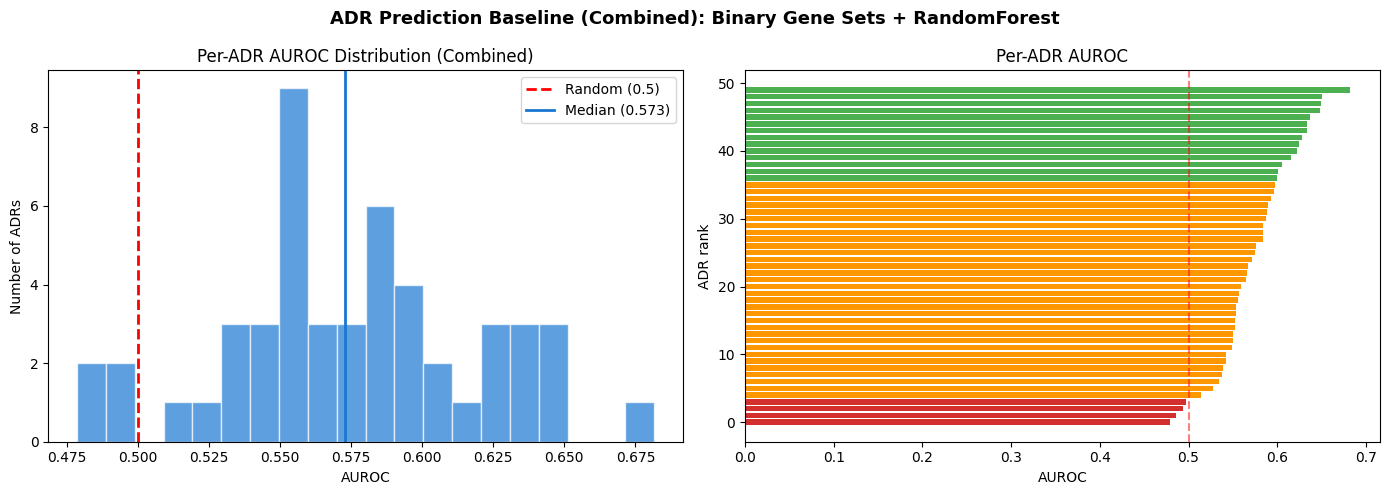

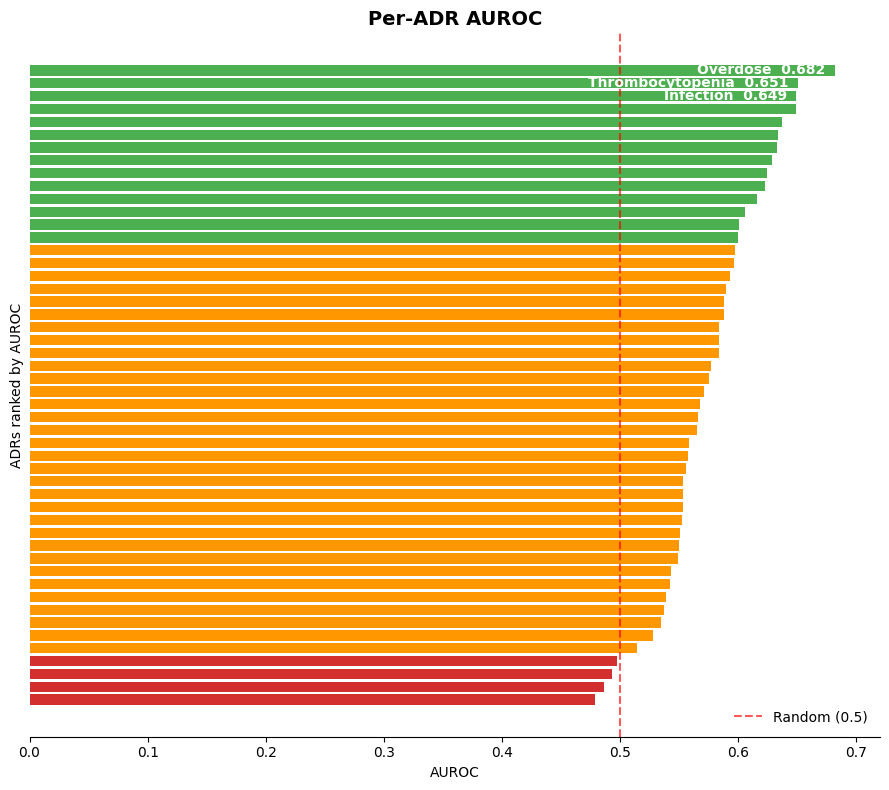


Combined summary:
  ADRs evaluated: 50
  Mean AUROC: 0.576
  Median AUROC: 0.573
  ADRs with AUROC > 0.6: 14
  ADRs with AUROC > 0.7: 0

Further reading: SEP-L1000 (Wang et al., Bioinformatics, 2016).


In [16]:
# Visualize AUROC distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(combined_df["auroc"].dropna(), bins=20, color="#1976D2", alpha=0.7, edgecolor="white")
ax1.axvline(x=0.5, color="red", linestyle="--", linewidth=2, label="Random (0.5)")
ax1.axvline(x=combined_df["auroc"].median(), color="#1976D2", linestyle="-", linewidth=2,
            label=f"Median ({combined_df['auroc'].median():.3f})")
ax1.set_xlabel("AUROC")
ax1.set_ylabel("Number of ADRs")
ax1.set_title("Per-ADR AUROC Distribution (Combined)")
ax1.legend()

sorted_combined = combined_df.dropna(subset=["auroc"]).sort_values("auroc")
colors = ["#D32F2F" if x < 0.5 else "#FF9800" if x < 0.6 else "#4CAF50" if x < 0.7 else "#1976D2" for x in sorted_combined["auroc"]]
ax2.barh(range(len(sorted_combined)), sorted_combined["auroc"], color=colors, height=0.8)
ax2.axvline(x=0.5, color="red", linestyle="--", alpha=0.5)
ax2.set_xlabel("AUROC")
ax2.set_ylabel("ADR rank")
ax2.set_title("Per-ADR AUROC")

fig.suptitle("ADR Prediction Baseline (Combined): Binary Gene Sets + RandomForest",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(DATA_DIR / "baseline_combined_auroc.png", dpi=150, bbox_inches="tight")
plt.show()

# Standalone ranked AUROC figure for presentation use
fig, ax = plt.subplots(figsize=(9, 8))
y_positions = np.arange(len(sorted_combined))
ax.barh(y_positions, sorted_combined["auroc"], color=colors, height=0.8)
ax.axvline(x=0.5, color="red", linestyle="--", linewidth=1.5, alpha=0.65, label="Random (0.5)")

for row_index, row in sorted_combined.nlargest(3, "auroc").iterrows():
    y = sorted_combined.index.get_loc(row_index)
    ax.text(
        row["auroc"] - 0.008, y,
        f"{row['adr_name']}  {row['auroc']:.3f}",
        ha="right", va="center", color="white", fontsize=10, fontweight="bold",
    )

ax.set_xlabel("AUROC")
ax.set_ylabel("ADRs ranked by AUROC")
ax.set_yticks([])
ax.set_xlim(0, 0.72)
ax.set_title("Per-ADR AUROC", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.savefig(DATA_DIR / "baseline_per_adr_auroc.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nCombined summary:")
print(f"  ADRs evaluated: {len(combined_df)}")
print(f"  Mean AUROC: {combined_df['auroc'].mean():.3f}")
print(f"  Median AUROC: {combined_df['auroc'].median():.3f}")
print(f"  ADRs with AUROC > 0.6: {(combined_df['auroc'] > 0.6).sum()}")
print(f"  ADRs with AUROC > 0.7: {(combined_df['auroc'] > 0.7).sum()}")
print("\nFurther reading: SEP-L1000 (Wang et al., Bioinformatics, 2016).")

## Per-Dataset Evaluation

Run the same classifier independently on each Perturb-Seqr drug perturbation dataset to compare predictive performance across platforms.
To Do: leave-one-out ablation

In [17]:
dataset_results = {}
for gmt_file in sorted(GMT_DIR.glob("*.gmt.gz")):
    dataset = gmt_file.stem.replace(".gmt", "")
    if dataset in SKIP_DATASETS:
        continue

    X_ds = build_feature_matrix(gmt_file, trainable_items=trainable_names, normalize_gene=to_human)
    if X_ds is None or len(X_ds) < 30:
        print(f"{dataset}: only {len(X_ds) if X_ds is not None else 0} drugs, skipping")
        continue

    print(f"\n{'='*60}")
    print(f"{dataset}: {X_ds.shape[0]} drugs × {X_ds.shape[1]} features")
    print(f"{'='*60}")

    df = evaluate_targets(X_ds, adr_target_builder, adr_targets, verbose=False)
    if len(df) == 0:
        print("  No ADRs with enough positive drugs")
        continue
    dataset_results[dataset] = df
    stats = summarize_aurocs(df)
    best = df.loc[df['auroc'].idxmax()]
    print(f"  ADRs evaluated: {stats['n']}")
    print(f"  Mean AUROC: {stats['mean']:.3f}")
    print(f"  Median AUROC: {stats['median']:.3f}")
    print(f"  Best: {best['adr_name']} ({best['auroc']:.3f})")


creeds-chem: 124 drugs × 33762 features


  ADRs evaluated: 50
  Mean AUROC: 0.499
  Median AUROC: 0.488
  Best: Gas (0.649)



deepcover-moa: 189 drugs × 11926 features


  ADRs evaluated: 50
  Mean AUROC: 0.515
  Median AUROC: 0.504
  Best: Thrombocytopenia (0.681)



ginkgo-bioworks: 128 drugs × 36476 features


...

  ADRs evaluated: 50
  Mean AUROC: 0.493
  Median AUROC: 0.497
  Best: Flu (0.587)



sciplex: 46 drugs × 18498 features


  ADRs evaluated: 44
  Mean AUROC: 0.490
  Median AUROC: 0.481
  Best: Stevens-Johnson syndrome (0.703)



tahoe-100m: 155 drugs × 36392 features


  ADRs evaluated: 50
  Mean AUROC: 0.507
  Median AUROC: 0.498
  Best: Pyrexia (0.654)


## Per-Dataset Comparison

In [18]:
# Summary table: per-dataset stats + combined row
def _row(dataset_name, trainable_count, df):
    stats = summarize_aurocs(df)
    return {
        "Dataset": dataset_name,
        "Trainable drugs": trainable_count,
        "ADRs evaluated": stats["n"],
        "Mean AUROC": stats["mean"],
        "Median AUROC": stats["median"],
        "Max AUROC": stats["max"],
        "> 0.6": stats["above_0.6"],
        "> 0.7": stats["above_0.7"],
    }

summary = [
    _row(ds, len(per_dataset_drugs[ds] & trainable_names), df)
    for ds, df in dataset_results.items()
]
summary.append(_row("ALL COMBINED", len(trainable), combined_df))
summary_df = pd.DataFrame(summary).sort_values("Mean AUROC", ascending=False)
display(summary_df)

,Dataset,Trainable drugs,ADRs evaluated,Mean AUROC,Median AUROC,Max AUROC,> 0.6,> 0.7
9,ALL COMBINED,1011,50,0.575651,0.572971,0.681605,14,0
3,lincs-l1000-cp,720,50,0.516159,0.511311,0.615405,1,0
1,deepcover-moa,189,50,0.515206,0.504433,0.681008,3,0
8,tahoe-100m,155,50,0.506683,0.498126,0.653986,2,0
5,nibr-drug-seq,344,50,0.505458,0.501482,0.588872,0,0
4,microarrays-cmap,414,50,0.505318,0.500984,0.570345,0,0
2,ginkgo-bioworks,128,50,0.504131,0.508974,0.617196,1,0
0,creeds-chem,124,50,0.499082,0.487888,0.648874,4,0
6,rummageo-chem,161,50,0.492744,0.496668,0.587234,0,0
7,sciplex,46,44,0.490214,0.480645,0.703333,9,1


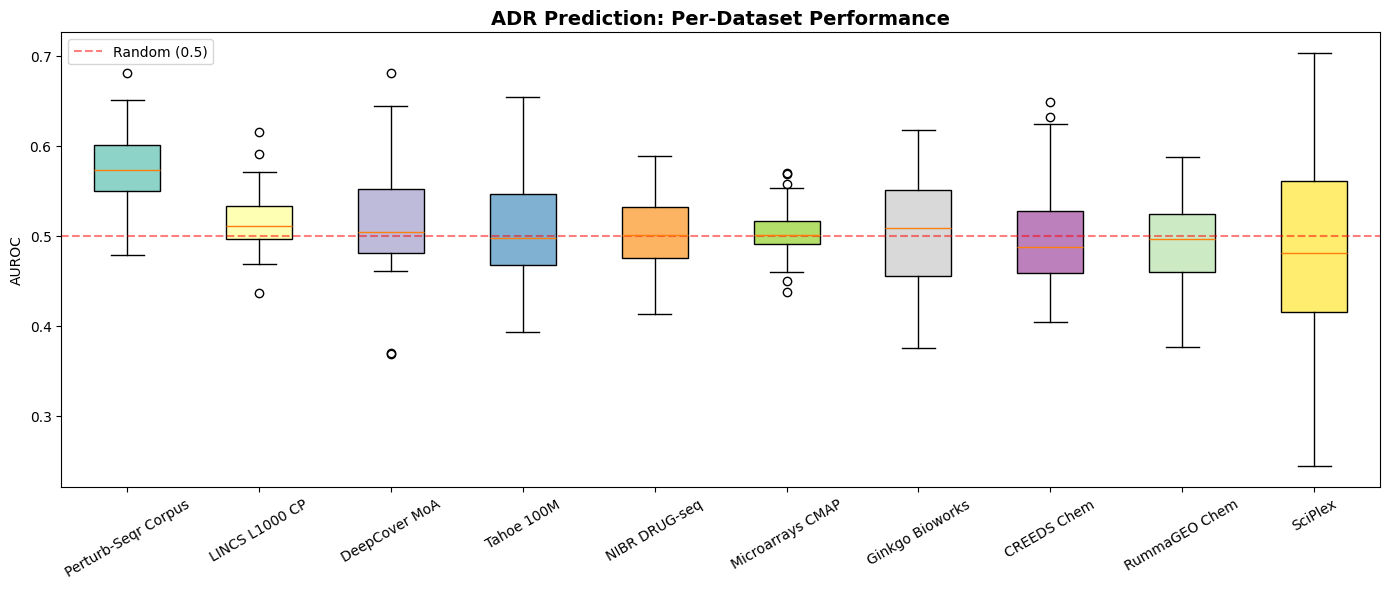

In [19]:
# Box plot comparing AUROC distributions per dataset
fig, ax = plt.subplots(figsize=(14, 6))

dataset_labels = {
    "ALL COMBINED": "Perturb-Seqr Corpus",
    "creeds-chem": "CREEDS Chem",
    "deepcover-moa": "DeepCover MoA",
    "ginkgo-bioworks": "Ginkgo Bioworks",
    "lincs-l1000-cp": "LINCS L1000 CP",
    "microarrays-cmap": "Microarrays CMAP",
    "nibr-drug-seq": "NIBR DRUG-seq",
    "rummageo-chem": "RummaGEO Chem",
    "sciplex": "SciPlex",
    "tahoe-100m": "Tahoe 100M",
}
dataset_keys = summary_df["Dataset"].tolist()
box_data = []
for ds in dataset_keys:
    if ds == "ALL COMBINED":
        box_data.append(combined_df["auroc"].dropna().values)
    else:
        box_data.append(dataset_results[ds]["auroc"].dropna().values)

tick_labels = [dataset_labels.get(ds, ds) for ds in dataset_keys]
bp = ax.boxplot(box_data, tick_labels=tick_labels, patch_artist=True, vert=True)
colors = plt.cm.Set3(np.linspace(0, 1, len(dataset_keys)))
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)

ax.axhline(y=0.5, color="red", linestyle="--", alpha=0.5, label="Random (0.5)")
ax.set_ylabel("AUROC")
ax.set_title("ADR Prediction: Per-Dataset Performance", fontsize=14, fontweight="bold")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.tight_layout()
plt.savefig(DATA_DIR / "baseline_per_dataset.png", dpi=150, bbox_inches="tight")
plt.show()

## Novel ADR Predictions per Drug

Collect out-of-fold predictions for every drug × ADR pair. For each drug, filter out ADRs it is **already known** to cause (per OnSIDES), leaving only **novel** predicted side effects — analogous to the "filter known" view in [SEP-L1000](https://maayanlab.net/SEP-L1000/).

In [20]:
# Collect OOF predictions for every evaluated ADR
oof_by_adr = {}
for adr_id, _ in top_adrs:
    adr_name = meddra_names[adr_id]
    y_adr = build_target(adr_id, X, name_to_rxnorm, rxnorm_to_adrs)
    n_pos = int(y_adr.sum())
    if n_pos < 10 or n_pos > len(y_adr) - 10:
        continue
    try:
        result = cv_auroc(X.values, y_adr)
    except Exception:
        continue
    oof_by_adr[adr_id] = {
        "name": adr_name,
        "auroc": result.mean_auroc,
        "oof": result.oof_predictions,
        "y": y_adr,
    }

# Build drug × ADR prediction probability matrix and known-label matrix
adr_order = sorted(oof_by_adr.keys(), key=lambda a: -oof_by_adr[a]["auroc"])
adr_cols = [oof_by_adr[a]["name"] for a in adr_order]

pred_matrix = pd.DataFrame(
    {oof_by_adr[a]["name"]: oof_by_adr[a]["oof"] for a in adr_order},
    index=X.index,
)
known_matrix = pd.DataFrame(
    {oof_by_adr[a]["name"]: oof_by_adr[a]["y"] for a in adr_order},
    index=X.index,
)
auroc_by_name = {oof_by_adr[a]["name"]: oof_by_adr[a]["auroc"] for a in adr_order}

print(f"Prediction matrix: {pred_matrix.shape[0]} drugs × {pred_matrix.shape[1]} ADRs")
print(f"Known associations: {int(known_matrix.values.sum()):,}")
print(f"Novel predictions (prob > 0.5): {int(((pred_matrix > 0.5) & (known_matrix == 0)).values.sum()):,}")

Prediction matrix: 1011 drugs × 50 ADRs
Known associations: 21,972
Novel predictions (prob > 0.5): 4,808


In [21]:
def show_novel_predictions(drug_name: str, top_n: int = 20) -> pd.DataFrame:
    """Show predicted ADRs for a drug, filtering out known associations."""
    preds = pred_matrix.loc[drug_name]
    knowns = known_matrix.loc[drug_name]
    novel = preds[knowns == 0].sort_values(ascending=False).head(top_n)
    return pd.DataFrame({
        "ADR": novel.index,
        "Predicted Probability": novel.values,
        "ADR AUROC": [auroc_by_name[a] for a in novel.index],
    }).reset_index(drop=True)

def show_drug_profile(drug_name: str) -> None:
    """Full ADR profile for a drug: known vs novel."""
    preds = pred_matrix.loc[drug_name]
    knowns = known_matrix.loc[drug_name]
    n_known = int(knowns.sum())
    n_novel = int(((knowns == 0) & (preds > 0.5)).sum())
    print(f"{'─' * 60}")
    print(f"  {drug_name.upper()}  —  {n_known} known ADRs, {n_novel} novel (prob > 0.5)")
    print(f"{'─' * 60}")
    novel_df = show_novel_predictions(drug_name)
    display(novel_df)

In [22]:
# Example: novel predictions for selected FDA-approved drugs
for drug in ["dexamethasone", "cisplatin", "vorinostat", "trametinib", "sirolimus", "metformin"]:
    if drug in pred_matrix.index:
        show_drug_profile(drug)

────────────────────────────────────────────────────────────
  DEXAMETHASONE  —  35 known ADRs, 8 novel (prob > 0.5)
────────────────────────────────────────────────────────────


,ADR,Predicted Probability,ADR AUROC
0,Diarrhea,0.731482,0.634065
1,Rash,0.703795,0.576543
2,Vomiting,0.657218,0.600198
3,Constipation,0.585646,0.633049
4,Pyrexia,0.567116,0.628073
5,Anaemia,0.545143,0.636029
6,Cough,0.543031,0.605390
7,Abdominal pain,0.524013,0.600929
8,Pruritus,0.451044,0.555357
9,Hypotension,0.425900,0.537458


────────────────────────────────────────────────────────────
  CISPLATIN  —  33 known ADRs, 3 novel (prob > 0.5)
────────────────────────────────────────────────────────────


,ADR,Predicted Probability,ADR AUROC
0,Fatigue,0.622783,0.624564
1,Overdose,0.591350,0.681605
2,Hypertension,0.522619,0.596966
3,Thrombocytopenia,0.491385,0.650835
4,Edema,0.475229,0.648525
5,Stevens-Johnson syndrome,0.458247,0.596800
6,Arthralgia,0.425171,0.589692
7,Dyspepsia,0.405865,0.557161
8,DIC,0.388775,0.541949
9,Myalgia,0.387837,0.574910


────────────────────────────────────────────────────────────
  VORINOSTAT  —  16 known ADRs, 10 novel (prob > 0.5)
────────────────────────────────────────────────────────────


...

,ADR,Predicted Probability,ADR AUROC
0,Nervous system disorder,0.695284,0.542781
1,Gastrointestinal disorder,0.691831,0.615690
2,Overdose,0.653665,0.681605
3,Vascular disorder,0.612006,0.583804
4,Diarrhoea,0.578361,0.565709
5,Anaemia,0.576553,0.636029
6,Eye disorder,0.543646,0.583830
7,Cardiac disorder,0.496686,0.553625
8,Immune system disorder,0.475257,0.478678
9,Erythema,0.460900,0.567353


────────────────────────────────────────────────────────────
  SIROLIMUS  —  33 known ADRs, 2 novel (prob > 0.5)
────────────────────────────────────────────────────────────


,ADR,Predicted Probability,ADR AUROC
0,Nervous system disorder,0.670270,0.542781
1,Diarrhoea,0.543345,0.565709
2,Immune system disorder,0.486955,0.478678
3,Cardiac disorder,0.421049,0.553625
4,Dyspepsia,0.405766,0.557161
5,Asthenia,0.399257,0.587788
6,Stevens-Johnson syndrome,0.395121,0.596800
7,Myalgia,0.393199,0.574910
8,Hypotension,0.329535,0.537458
9,Dyspnoea,0.329385,0.553489


────────────────────────────────────────────────────────────
  METFORMIN  —  43 known ADRs, 1 novel (prob > 0.5)
────────────────────────────────────────────────────────────


,ADR,Predicted Probability,ADR AUROC
0,Cardiac disorder,0.519691,0.553625
1,Pyrexia,0.459975,0.628073
2,Insomnia,0.407036,0.571032
3,Dyspnoea,0.406401,0.553489
4,Anxiety,0.350654,0.558684
5,Depression,0.344871,0.528127
6,Tachycardia,0.301651,0.565132


## Predictions for Unlabeled Drugs

Train the model on all 1,021 OnSIDES-labeled drugs and predict ADRs for drugs with **no known side effects** — experimental compounds, tool molecules, and proprietary codes (e.g. NIBR NSN identifiers). Every prediction here is novel by definition.

In [23]:
# Build feature matrix for ALL drugs (not just trainable), using the same gene vocabulary
X_all = build_feature_matrix(GMT_DIR, skip_datasets=SKIP_DATASETS, normalize_gene=to_human)
unlabeled_drugs = sorted(set(X_all.index) - trainable_names)

print(f"Total drugs with signatures: {len(X_all)}")
print(f"Labeled (in OnSIDES): {len(trainable_names & set(X_all.index))}")
print(f"Unlabeled (no ADR labels): {len(unlabeled_drugs)}")

# Align unlabeled drugs to the training feature space
shared_cols = X.columns.intersection(X_all.columns)
X_unlabeled = X_all.loc[unlabeled_drugs, shared_cols].reindex(columns=X.columns, fill_value=0)
print(f"\nUnlabeled feature matrix: {X_unlabeled.shape}")
print(f"Shared features with training: {len(shared_cols)} / {len(X.columns)}")

Total drugs with signatures: 11969
Labeled (in OnSIDES): 1011
Unlabeled (no ADR labels): 10958



Unlabeled feature matrix: (10958, 41544)
Shared features with training: 41544 / 41544


In [24]:
# Train on all labeled drugs, predict for unlabeled drugs, for each top ADR
# Use only ADRs where the combined model had AUROC > 0.6 (meaningful signal)
good_adrs = {aid: info for aid, info in oof_by_adr.items() if info["auroc"] > 0.6}
print(f"Predicting {len(good_adrs)} ADRs with AUROC > 0.6 for {len(unlabeled_drugs)} unlabeled drugs...\n")

unlabeled_preds = {}
for adr_id, info in sorted(good_adrs.items(), key=lambda x: -x[1]["auroc"]):
    y_train = build_target(adr_id, X, name_to_rxnorm, rxnorm_to_adrs)
    n_comp = min(64, len(X) - 1, X.shape[1])
    cv = sk.model_selection.StratifiedKFold(n_splits=3, shuffle=True, random_state=rng)
    model = build_pipeline(cv, n_components=n_comp, random_state=rng)
    model.fit(X.values, y_train)
    probs = model.predict_proba(X_unlabeled.values)[:, 1]
    unlabeled_preds[info["name"]] = probs
    n_above = (probs > 0.5).sum()
    print(f"  {info['name']} (AUROC={info['auroc']:.3f}): {n_above} / {len(probs)} unlabeled drugs predicted positive")

unlabeled_pred_df = pd.DataFrame(unlabeled_preds, index=unlabeled_drugs)
print(f"\nPrediction matrix: {unlabeled_pred_df.shape}")

Predicting 14 ADRs with AUROC > 0.6 for 10958 unlabeled drugs...



  Overdose (AUROC=0.682): 4251 / 10958 unlabeled drugs predicted positive


  Thrombocytopenia (AUROC=0.651): 141 / 10958 unlabeled drugs predicted positive


  Infection (AUROC=0.649): 6842 / 10958 unlabeled drugs predicted positive


  Edema (AUROC=0.649): 70 / 10958 unlabeled drugs predicted positive


...

  UTI (AUROC=0.623): 10941 / 10958 unlabeled drugs predicted positive


  Gastrointestinal disorder (AUROC=0.616): 10946 / 10958 unlabeled drugs predicted positive


  Cough (AUROC=0.605): 116 / 10958 unlabeled drugs predicted positive


  Abdominal pain (AUROC=0.601): 3733 / 10958 unlabeled drugs predicted positive


  Vomiting (AUROC=0.600): 8971 / 10958 unlabeled drugs predicted positive

Prediction matrix: (10958, 14)


In [25]:
# Show predicted ADR profiles for specific unlabeled drugs
def show_unlabeled_profile(drug_name: str, top_n: int = 15) -> None:
    """Show top predicted ADRs for an unlabeled drug."""
    preds = unlabeled_pred_df.loc[drug_name].sort_values(ascending=False).head(top_n)
    print(f"\n{'─' * 60}")
    print(f"  {drug_name.upper()}  (unlabeled — no known ADRs)")
    print(f"  Predicted positive for {(unlabeled_pred_df.loc[drug_name] > 0.5).sum()} / {len(good_adrs)} ADRs")
    print(f"{'─' * 60}")
    df = pd.DataFrame({
        "ADR": preds.index,
        "Predicted Probability": preds.values,
        "ADR AUROC": [good_adrs[next(a for a, i in good_adrs.items() if i["name"] == name)]["auroc"] for name in preds.index],
    }).reset_index(drop=True)
    display(df)

# NIBR NSN codes (proprietary pre-clinical compounds)
nsn_drugs = sorted(d for d in unlabeled_drugs if d.startswith("nsn:"))
print(f"NIBR NSN codes in unlabeled set: {len(nsn_drugs)}")
for drug in nsn_drugs[:5]:
    show_unlabeled_profile(drug)

# Named experimental compounds
named_examples = ["17-aag", "nutlin-3", "jq1", "i-bet-762", "trichostatin a", "wortmannin", 
                  "geldanamycin", "staurosporine", "brefeldin a", "thapsigargin"]
available = [d for d in named_examples if d in unlabeled_pred_df.index]
print(f"\n\n{'=' * 60}")
print(f"Named experimental compounds")
print(f"{'=' * 60}")
for drug in available:
    show_unlabeled_profile(drug)

NIBR NSN codes in unlabeled set: 482

────────────────────────────────────────────────────────────
  NSN:AA-12-SS68  (unlabeled — no known ADRs)
  Predicted positive for 2 / 14 ADRs
────────────────────────────────────────────────────────────


,ADR,Predicted Probability,ADR AUROC
0,Gastrointestinal disorder,0.627553,0.615690
1,UTI,0.606648,0.622737
2,Vomiting,0.474986,0.600198
3,Constipation,0.468764,0.633049
4,Infection,0.456996,0.649001
5,Fatigue,0.405039,0.624564
6,Diarrhea,0.405007,0.634065
7,Overdose,0.393913,0.681605
8,Abdominal pain,0.388151,0.600929
9,Cough,0.331710,0.605390



────────────────────────────────────────────────────────────
  NSN:AA-16-HV95  (unlabeled — no known ADRs)
  Predicted positive for 8 / 14 ADRs
────────────────────────────────────────────────────────────


,ADR,Predicted Probability,ADR AUROC
0,UTI,0.814279,0.622737
1,Gastrointestinal disorder,0.648959,0.615690
2,Infection,0.579760,0.649001
3,Vomiting,0.568259,0.600198
4,Diarrhea,0.536271,0.634065
5,Abdominal pain,0.519021,0.600929
6,Overdose,0.508594,0.681605
7,Fatigue,0.506592,0.624564
8,Constipation,0.464693,0.633049
9,Cough,0.394818,0.605390



────────────────────────────────────────────────────────────
  NSN:AA-49-HG46  (unlabeled — no known ADRs)
  Predicted positive for 5 / 14 ADRs
────────────────────────────────────────────────────────────


...

,ADR,Predicted Probability,ADR AUROC
0,UTI,0.790727,0.622737
1,Vomiting,0.774618,0.600198
2,Gastrointestinal disorder,0.677978,0.615690
3,Infection,0.655744,0.649001
4,Constipation,0.649544,0.633049
5,Diarrhea,0.580414,0.634065
6,Abdominal pain,0.579528,0.600929
7,Fatigue,0.547390,0.624564
8,Pyrexia,0.529403,0.628073
9,Overdose,0.434780,0.681605



────────────────────────────────────────────────────────────
  BREFELDIN A  (unlabeled — no known ADRs)
  Predicted positive for 10 / 14 ADRs
────────────────────────────────────────────────────────────


,ADR,Predicted Probability,ADR AUROC
0,UTI,0.789513,0.622737
1,Gastrointestinal disorder,0.731397,0.615690
2,Vomiting,0.723928,0.600198
3,Infection,0.642071,0.649001
4,Overdose,0.604474,0.681605
5,Constipation,0.591607,0.633049
6,Fatigue,0.567780,0.624564
7,Abdominal pain,0.553706,0.600929
8,Pyrexia,0.552958,0.628073
9,Diarrhea,0.552460,0.634065



────────────────────────────────────────────────────────────
  THAPSIGARGIN  (unlabeled — no known ADRs)
  Predicted positive for 10 / 14 ADRs
────────────────────────────────────────────────────────────


,ADR,Predicted Probability,ADR AUROC
0,UTI,0.775561,0.622737
1,Diarrhea,0.682938,0.634065
2,Vomiting,0.678767,0.600198
3,Gastrointestinal disorder,0.662266,0.615690
4,Infection,0.653207,0.649001
5,Fatigue,0.600324,0.624564
6,Abdominal pain,0.563492,0.600929
7,Overdose,0.560981,0.681605
8,Thrombocytopenia,0.550238,0.650835
9,Pyrexia,0.534565,0.628073
